# 02 · Stints, tyre degradation and pit loss

**Cleaning.** Keep representative laps only:

* dry compound;
* not lap 1, an in-lap or an out-lap;
* green flag throughout (no SC, VSC or red flag) and no rain;
* within 107 % of the driver's stint median.

Then **fuel-correct** them. A car burns roughly 1.5–1.8 kg of fuel per lap, worth about
0.03 s per lap (an assumption, exposed as `FUEL_EFFECT_S_PER_LAP`), so each lap is expressed as
if run on the final lap's fuel load.

**Per-race tyre model.** For each race we fit one fixed-effects regression on clean laps:

`fuel-corrected lap = driver effect + compound offset + compound slope × tyre age + β × lap`

* the *driver effect* absorbs car and driver pace;
* *β* absorbs track evolution (rubbering-in);
* the *offset* and *slope* of each compound come from drivers who switched compounds, which
  the rules force every driver to do.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from f1tyres import plots
from f1tyres.analysis import (
    clean_laps,
    degradation_table,
    driver_strategies,
    fit_race_tyre_model,
    observed_max_stint,
    pit_loss,
    stints,
)
from f1tyres.config import DATA_PROCESSED
from f1tyres.data import load_tables

plots.apply_style()
t = load_tables()
laps, results = t["laps"], t["results"]
clean = clean_laps(laps)
st = stints(laps)
print(f"{len(clean):,} clean laps of {len(laps):,} ({len(clean) / len(laps):.0%})")
st.to_parquet(DATA_PROCESSED / "stints.parquet", index=False)

77,263 clean laps of 100,950 (77%)


## A race in stints

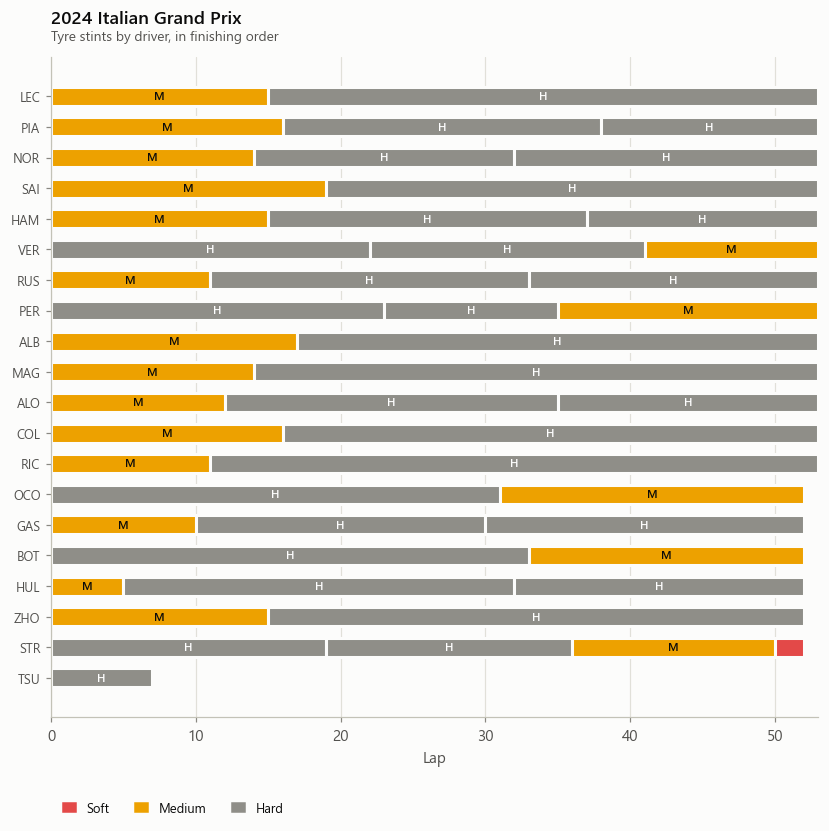

In [2]:
EXAMPLE = ("2024", "Italian Grand Prix")
rid = st[(st["Season"] == int(EXAMPLE[0])) & (st["EventName"] == EXAMPLE[1])]["RaceId"].iloc[0]
order = (results[(results["Season"] == int(EXAMPLE[0])) & (results["EventName"] == EXAMPLE[1])]
         .sort_values("Position")["Abbreviation"].tolist())
fig = plots.strategy_timeline(st[st["RaceId"] == rid], order, f"{EXAMPLE[0]} {EXAMPLE[1]}")
plots.save(fig, "strategy_timeline")
plt.show()

In [3]:
strat = driver_strategies(st, results)
strat.to_parquet(DATA_PROCESSED / "driver_strategies.parquet", index=False)
winners = strat[strat["Position"] == 1]
pd.crosstab(winners["Season"], winners["Stops"]).rename(columns=lambda s: f"{s} stop(s)")

Stops,0 stop(s),1 stop(s),2 stop(s),3 stop(s),4 stop(s),5 stop(s),6 stop(s)
Season,,,,,,,
2022,0,7,9,5,1,0,0
2023,0,7,9,3,2,0,1
2024,1,11,10,2,0,0,0
2025,0,12,9,1,0,2,0


## Degradation in one race

{'MEDIUM': (0.409, 33.8), 'HARD': (0.0, 50.9)} | track evolution -32 ms/lap | fit RMSE 0.44 s


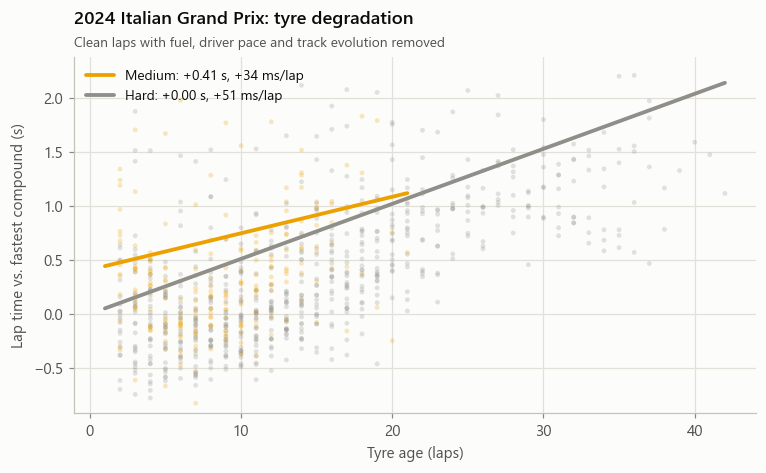

In [4]:
race = clean[clean["RaceId"] == rid]
model = fit_race_tyre_model(race, max_stint=observed_max_stint(st[st["RaceId"] == rid]))
print({c: (round(o, 3), round(s * 1000, 1)) for c, (o, s) in model.compounds.items()},
      f"| track evolution {model.track_evolution * 1000:.0f} ms/lap | fit RMSE {model.rmse:.2f} s")
fig = plots.race_degradation_curves(race, model, f"{EXAMPLE[0]} {EXAMPLE[1]}: tyre degradation")
plots.save(fig, "race_degradation")
plt.show()

## Degradation across every race

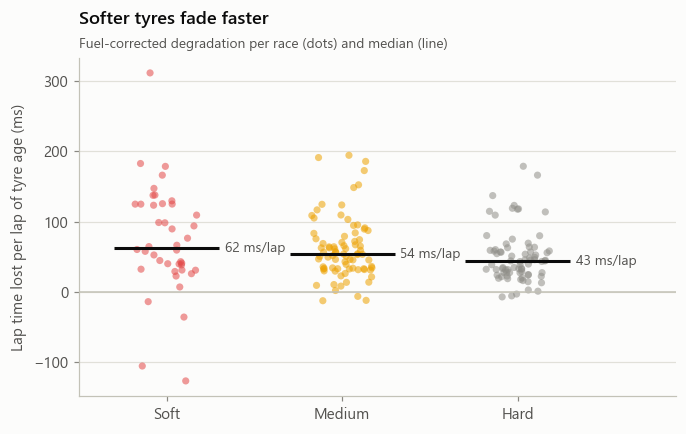

In [5]:
deg = degradation_table(clean, st)
deg.to_parquet(DATA_PROCESSED / "degradation.parquet", index=False)
fig = plots.degradation_summary(deg)
plots.save(fig, "degradation_summary")
plt.show()

In [6]:
summary = deg.groupby("Compound").agg(
    races=("RaceId", "nunique"),
    median_offset_s=("Offset", "median"),
    median_deg_ms_per_lap=("DegSlope", lambda s: s.median() * 1000),
    longest_stint_median=("MaxStint", "median"),
).reindex(["SOFT", "MEDIUM", "HARD"])
summary.round(2)

,races,median_offset_s,median_deg_ms_per_lap,longest_stint_median
Compound,,,,
SOFT,42,0.0,62.38,25.0
MEDIUM,81,0.0,53.85,32.0
HARD,77,0.2,43.29,40.0


Softs are the fastest compound but lose time quickest. Hards are slowest over one lap but last
longest. Per-race slopes are noisy: track evolution, traffic and drivers managing their tyres all
blur them, and a few come out slightly negative. The *median* across races is the robust number.

### Does a hotter track mean more degradation?

In [7]:
deg.groupby("Compound")[["DegSlope", "TrackTemp"]].apply(
    lambda d: d["DegSlope"].corr(d["TrackTemp"], method="spearman")).rename("spearman_rho").round(2)

Compound
HARD     -0.10
MEDIUM   -0.08
SOFT     -0.31
Name: spearman_rho, dtype: float64

**Not in any simple way.** Across races, track temperature barely correlates with the measured
degradation rate. Pirelli picks softer or harder compounds for each circuit, and teams adjust
set-up and tyre management to the conditions, which hides a raw temperature effect.


## What a pit stop costs

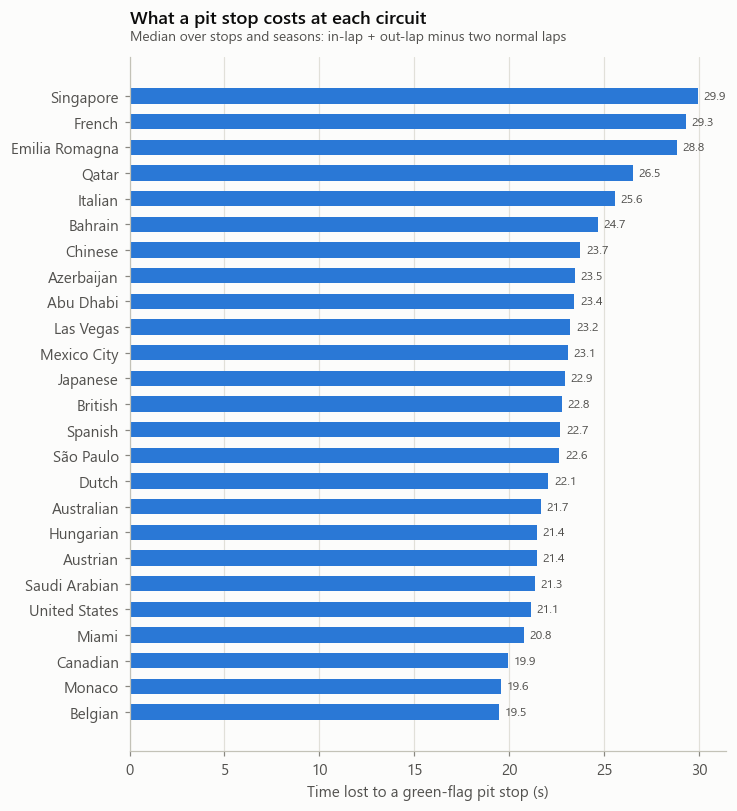

Median green-flag pit loss: 22.9 s (range 19.5–29.9 s by circuit)


In [8]:
pl = pit_loss(laps)
pl.to_parquet(DATA_PROCESSED / "pit_loss.parquet", index=False)
fig = plots.pit_loss_by_circuit(pl)
plots.save(fig, "pit_loss")
plt.show()
print(f"Median green-flag pit loss: {pl['PitLoss'].median():.1f} s "
      f"(range {pl.groupby('EventName')['PitLoss'].median().min():.1f}–"
      f"{pl.groupby('EventName')['PitLoss'].median().max():.1f} s by circuit)")